# **Project: Strategic Customer Segmentation for E-commerce Growth**
## **Framework: CRISP-DM | Methodology: RFM & K-Means Clustering**

---

## **1. Business Understanding**
In the modern e-commerce landscape, "one-size-fits-all" marketing is inefficient. This project focuses on **Customer Analytics** to drive retention and profitability. By analyzing historical transaction data, we aim to move from descriptive statistics to actionable business intelligence.

### **The Challenge**
As a Business Analyst, the goal is to answer:
* Who are our most valuable customers?
* Which customers are at the highest risk of churning?
* How can the **FP&A (Financial Planning & Analysis)** team better forecast revenue by understanding customer segments?

### **The Objective**
To build a data-driven segmentation model using **Recency, Frequency, and Monetary (RFM)** metrics and **Unsupervised Machine Learning (K-Means)** to categorize customers into distinct behavioral groups.

---

## **2. Methodology: CRISP-DM**
This project follows the **Cross-Industry Standard Process for Data Mining (CRISP-DM)**, the gold standard for professional data science workflows:

1.  **Business Understanding:** Defining KPIs and project goals. (Current Phase)
2.  **Data Understanding:** Exploring the Olist E-commerce dataset (100k+ orders).
3.  **Data Preparation:** Cleaning, merging relational tables, and feature engineering RFM values.
4.  **Modeling:** Implementing K-Means Clustering to identify natural customer groupings.
5.  **Evaluation:** Validating clusters using the Elbow Method and Silhouette Analysis.
6.  **Deployment:** Translating data clusters into strategic business recommendations.

---

## **3. Technical Stack**
* **Environment:** Google Colab / Python 3.x
* **Data Manipulation:** `pandas`, `numpy`
* **Visualization:** `seaborn`, `matplotlib`
* **Machine Learning:** `scikit-learn` (StandardScaler, KMeans)

---

In [3]:
import pandas as pd

# Load the core datasets (Ensure these are uploaded to your Colab session)
customers = pd.read_csv('/content/olist_customers_dataset[1].csv')
orders = pd.read_csv('/content/olist_orders_dataset[1].csv')
payments = pd.read_csv('/content/olist_order_payments_dataset[1].csv')

# 1. Merge Customers and Orders on customer_id
df = pd.merge(orders, customers, on='customer_id')

# 2. Merge with Payments on order_id
df = pd.merge(df, payments, on='order_id')

# 3. Convert date columns to datetime objects
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

print(f"Dataset Loaded. Shape: {df.shape}")
df.head()

Dataset Loaded. Shape: (103886, 16)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,credit_card,1,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,3,voucher,1,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,2,voucher,1,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,boleto,1,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,credit_card,3,179.12


In [4]:
import pandas as pd

# Using the exact filenames from your sidebar screenshot
customers = pd.read_csv('olist_customers_dataset[1].csv')
orders = pd.read_csv('olist_orders_dataset[1].csv')
payments = pd.read_csv('olist_order_payments_dataset[1].csv')

# Merge logic (same as before)
df = pd.merge(orders, customers, on='customer_id')
df = pd.merge(df, payments, on='order_id')
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

print(f"Dataset Loaded. Shape: {df.shape}")

Dataset Loaded. Shape: (103886, 16)


In [5]:
import datetime as dt

# 1. Set the 'Snapshot Date' to one day after the most recent purchase
snapshot_date = df['order_purchase_timestamp'].max() + dt.timedelta(days=1)

# 2. Aggregate data by unique customer
rfm = df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days,
    'order_id': 'nunique',
    'payment_value': 'sum'
})

# 3. Rename columns for business clarity
rfm.rename(columns={
    'order_purchase_timestamp': 'Recency',
    'order_id': 'Frequency',
    'payment_value': 'Monetary'
}, inplace=True)

# 4. Filter out any potential outliers or zero-value transactions
rfm = rfm[rfm['Monetary'] > 0]

print("RFM Table Summary:")
display(rfm.describe())
rfm.head()

RFM Table Summary:


,Recency,Frequency,Monetary
count,96093.000000,96093.000000,96093.000000
mean,288.735766,1.034810,166.597693
std,153.405510,0.214387,231.430072
min,1.000000,1.000000,9.590000
25%,164.000000,1.000000,63.130000
50%,269.000000,1.000000,108.000000
75%,398.000000,1.000000,183.530000
max,773.000000,17.000000,13664.080000


,Recency,Frequency,Monetary
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,161,1,141.90
0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,27.19
0000f46a3911fa3c0805444483337064,586,1,86.22
0000f6ccb0745a6a4b88665a16c9f078,370,1,43.62
0004aac84e0df4da2b147fca70cf8255,337,1,196.89


In [6]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Apply Log Transformation to handle skewness
# We use log1p (log of 1+x) to avoid issues if there were any 0 values
rfm_log = np.log1p(rfm)

# 2. Initialize the StandardScaler
scaler = StandardScaler()

# 3. Fit and Transform the data
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to a DataFrame for easier handling
rfm_scaled_df = pd.DataFrame(rfm_scaled, index=rfm.index, columns=rfm.columns)

print("Data Scaled and Normalized. First 5 rows:")
display(rfm_scaled_df.head())

Data Scaled and Normalized. First 5 rows:


,Recency,Frequency,Monetary
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,-0.672010,-0.173596,0.282059
0000b849f77a49e4a4ce2b2a4ca5be3f,-0.642257,-0.173596,-1.717816
0000f46a3911fa3c0805444483337064,1.415560,-0.173596,-0.326230
0000f6ccb0745a6a4b88665a16c9f078,0.671577,-0.173596,-1.152029
0004aac84e0df4da2b147fca70cf8255,0.520524,-0.173596,0.683181


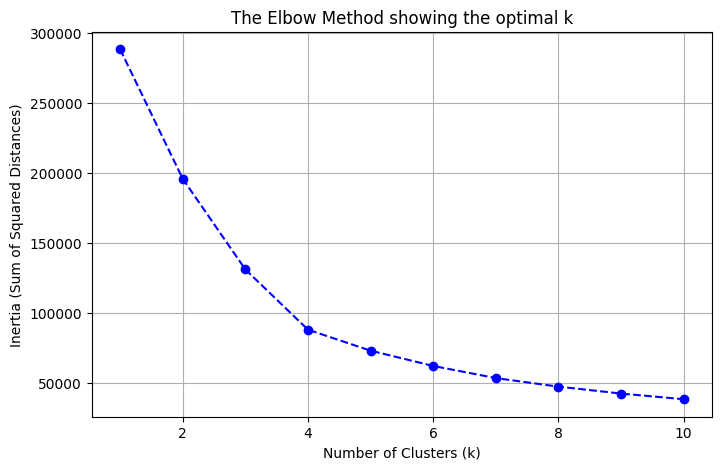

In [8]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Initialize an empty list to store 'Inertia' (Within-Cluster Sum of Squares)
inertia = []
range_clusters = range(1, 11)

# 2. Run KMeans for different numbers of clusters
for k in range_clusters:
    # n_init=10 ensures the algorithm runs with 10 different centroid seeds to find the best one
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(rfm_scaled_df)
    inertia.append(kmeans.inertia_)

# 3. Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range_clusters, inertia, marker='o', linestyle='--', color='b')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Sum of Squared Distances)')
plt.title('The Elbow Method showing the optimal k')
plt.grid(True)
plt.show()

In [9]:
# 1. Apply KMeans with the chosen number of clusters (3)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled_df)

# 2. View the mean values for each cluster to understand their characteristics
cluster_analysis = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

print("Cluster Characteristics:")
display(cluster_analysis)

Cluster Characteristics:


Recency Frequency Monetary       
           mean      mean     mean  count
Cluster                                  
0        269.21      2.12   314.99   2997
1        376.59      1.00   154.61  60009
2        131.17      1.00   174.90  33087

In [10]:
import plotly.express as px

# We use the original 'rfm' dataframe but add the 'Cluster' labels
# We'll also rename the clusters to their persona names for the plot
cluster_map = {
    0: 'Champions (High Freq/High Spend)',
    1: 'Hibernating (Old/Low Spend)',
    2: 'Potential (Recent/Single Buy)'
}
rfm['Segment'] = rfm['Cluster'].map(cluster_map)

# Create a 3D Scatter plot
fig = px.scatter_3d(rfm, x='Recency', y='Frequency', z='Monetary',
                    color='Segment',
                    title='3D RFM Customer Segments',
                    opacity=0.6,
                    height=800)

fig.show()

# **Project Conclusion: Strategic Business Recommendations**

Based on the RFM K-Means clustering analysis of the Olist E-commerce dataset, we have identified three critical customer segments. These insights provide a roadmap for personalized marketing and financial forecasting.

### **1. The "Champions" (Segment 0)**
* **Profile:** Highest frequency (2.12 avg) and highest spend ($314 avg). These are your only repeat customers.
* **FP&A Insight:** This segment represents the most "predictable" revenue stream. High retention here is vital for maintaining a healthy LTV (Lifetime Value).
* **Strategy:** Implement a **VIP Loyalty Program**. Offer early access to new products or exclusive discounts to prevent them from switching to competitors.

### **2. The "Potential / Recent" (Segment 2)**
* **Profile:** Lowest recency (131 days). They are "fresh" but have only shopped once.
* **FP&A Insight:** This is the primary growth engine. Moving a customer from this segment to the "Champions" segment doubles their value to the business.
* **Strategy:** Trigger **Cross-Selling Campaigns**. Since they recently interacted with the brand, a personalized recommendation based on their first purchase can convert them into repeat buyers.

### **3. The "Hibernating" (Segment 1)**
* **Profile:** Highest recency (376 days) and low spend. They are effectively lost.
* **FP&A Insight:** These customers represent "Revenue Leakage." High volume in this segment indicates a potential issue with the product-market fit or post-purchase experience.
* **Strategy:** **Win-Back or Sunset**. Send a high-value discount code (e.g., "We Miss You - 25% Off"). If they do not respond, stop spending marketing dollars on this group to optimize CAC (Customer Acquisition Cost).

---

## **Final Reflection**
By moving beyond manual scoring and using **Unsupervised Machine Learning**, we discovered that the frequency of purchase (2 vs 1) is a more powerful differentiator for this specific business than monetary value alone. This structured CRISP-DM approach ensures that data science remains aligned with core business objectives.